In [1]:
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval maite-datasets
except Exception:
    pass

In [2]:
import numpy as np
import polars as pl
from dataeval_plots import plot
from IPython.display import display
from maite_datasets.image_classification import MilitaryVehicles

from dataeval import Metadata

# Load the classes from DataEval that are helpful for EDA
from dataeval.config import set_max_processes
from dataeval.core import image_stats, label_stats
from dataeval.flags import ImageStats
from dataeval.quality import Duplicates, Outliers

# Print all rows of dataframes
_ = pl.Config.set_tbl_rows(-1)

# Set the random value
rng = np.random.default_rng(213)

# Set multiprocessing for DataEval stats
set_max_processes(4)

In [3]:
# Helper method to plot sample images by class
def plot_sample_images_by_class(dataset, image_indices_per_class) -> None:
    import matplotlib.pyplot as plt

    # Plot random images from each category
    _, axs = plt.subplots(6, 4, figsize=(8, 12))

    for ax, (category, indices) in zip(axs.flat, image_indices_per_class.items(), strict=False):
        # Randomly select an index from the list of indices
        ax.imshow(dataset[rng.choice(indices)][0].transpose(1, 2, 0))
        ax.set_title(dataset.index2label[category])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Helper method to plot images of interest
def plot_sample_outlier_images_by_metric(dataset, outlier_result, metric, layout) -> None:
    import matplotlib.gridspec as gridspec
    import matplotlib.pyplot as plt
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    # Filter outliers DataFrame for the specific metric
    metric_outliers = outlier_result.data().filter(pl.col("metric_name") == metric)

    if metric_outliers.is_empty():
        print(f"No images flagged for metric: {metric}")
        return

    # Get all metric values from stored calculation results to understand the distribution
    all_metric_values = outlier_result.calculation_results["stats"][metric]
    quantiles = np.quantile(all_metric_values, [0, 0.25, 0.5, 0.75, 1])
    median = quantiles[2]

    # Compute distance from median and sort by most extreme first
    ranked = (
        metric_outliers
        .unique(subset=["item_index"])
        .with_columns((pl.col("metric_value") - median).abs().alias("_distance"))
        .sort("_distance", descending=True)
        .drop("_distance")
    )

    # Determine number of samples to plot
    n_samples = min(int(np.prod(layout)), ranked.height)

    # Create figure with space for colorbar
    fig = plt.figure(figsize=(12, layout[0] * 4))
    gs = gridspec.GridSpec(
        layout[0],
        layout[1] + 1,
        width_ratios=[1] * layout[1] + [0.05],
        hspace=0.4,
        wspace=0.1,
        left=0.05,
        right=0.92,
        top=0.92,
        bottom=0.02,
    )

    # Create colormap normalization based on full metric distribution
    vmin, vmax = quantiles[0], quantiles[4]
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap("viridis")

    # Plot images
    for i in range(n_samples):
        row = ranked.row(i, named=True)
        img_id = row["item_index"]
        metric_value = row["metric_value"]
        color = cmap(norm(metric_value))

        ax = fig.add_subplot(gs[i // layout[1], i % layout[1]])
        ax.imshow(dataset[img_id][0].transpose(1, 2, 0))
        ax.set_xlabel(f"index: {img_id}\n{metric}: {np.round(metric_value, 3)}", fontsize=9, color="black")
        ax.set_xticks([])
        ax.set_yticks([])

        # Add colored border to indicate extremeness
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(5)
            spine.set_visible(True)

    # Add colorbar with quantile markers
    cbar_ax = fig.add_subplot(gs[:, -1])
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, cax=cbar_ax)
    cbar.set_ticks([])

    quantile_labels = ["Min (Q0)", "Q1 (25%)", "Median (Q2)", "Q3 (75%)", "Max (Q4)"]
    for q_val, q_label in zip(quantiles, quantile_labels, strict=False):
        cbar.ax.axhline(q_val, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
        cbar.ax.text(
            1.5,
            q_val,
            f"{q_label}\n{np.round(q_val, 2)}",
            va="center",
            fontsize=8,
            transform=cbar.ax.get_yaxis_transform(),
        )

    fig.suptitle(f'Outlier Images for "{metric}" (sorted by distance from median)', fontsize=12, y=0.99)
    plt.show()

In [4]:
# Download the data and then load it as a torch Tensor
ds = MilitaryVehicles("./data", image_set="train", download=True)
print(ds)

MilitaryVehicles Dataset
------------------------
    Transforms: []
    Image Set: train
    Metadata: {'id': 'MilitaryVehicles_train', 'index2label': {0: '2S19 MSTA', 1: '30N6E', 2: 'BM-30', 3: 'BMD', 4: 'BMP-1', 5: 'BMP-2', 6: 'BMP-T15', 7: 'BRDM', 8: 'BTR-60', 9: 'BTR-70', 10: 'BTR-80', 11: 'D-30', 12: 'Iskander', 13: 'MT LB', 14: 'Pantsir-S1', 15: 'Rs-24', 16: 'T-14', 17: 'T-62', 18: 'T-64', 19: 'T-72', 20: 'T-80', 21: 'T-90', 22: 'TOS-1', 23: 'Tornado'}, 'split': 'train'}
    Path: /builds/jatic/aria/dataeval/docs/source/notebooks/data/militaryvehicles
    Size: 7823


In [5]:
# Create the Metadata object
md = Metadata(ds)

lstats = label_stats(md.class_labels, md.item_indices, ds.index2label, image_count=len(ds))

# View per_class data as a DataFrame
pl.DataFrame({
    "class_name": list(ds.index2label.values()),
    "label_count": [lstats["label_counts_per_class"][k] for k in ds.index2label],
    "image_count": [lstats["image_counts_per_class"][k] for k in ds.index2label],
})

class_name,label_count,image_count
str,i64,i64
"""2S19 MSTA""",344,344
"""30N6E""",119,119
"""BM-30""",261,261
"""BMD""",322,322
"""BMP-1""",393,393
"""BMP-2""",390,390
"""BMP-T15""",341,341
"""BRDM""",389,389
"""BTR-60""",391,391


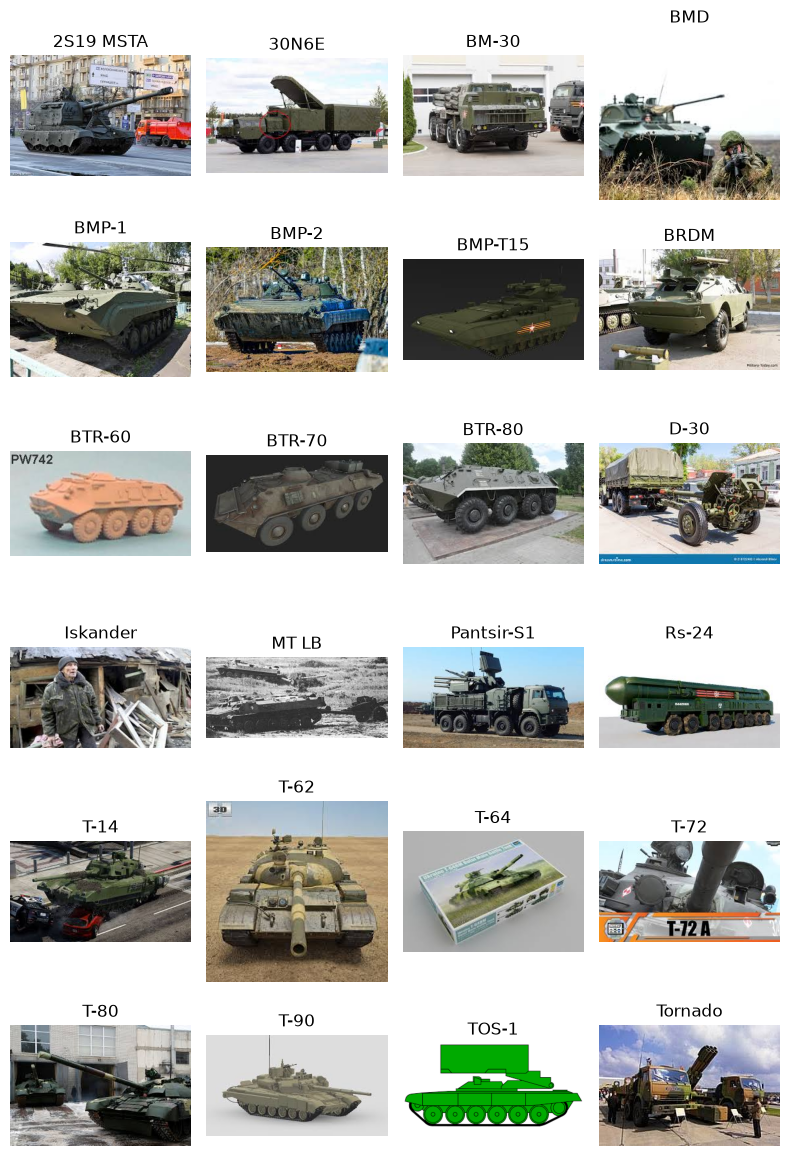

In [6]:
plot_sample_images_by_class(ds, lstats["image_indices_per_class"])

In [7]:
# This cell takes about 1-5 minutes to run depending on your hardware

# Initialize the Outliers class
outliers = Outliers(outlier_threshold="zscore")

# Find the extreme images
outlier_imgs = outliers.evaluate(ds, per_target=False)

# View the number of extreme images
print(f"Number of images with extreme values: {len(outlier_imgs)}")

Number of images with extreme values: 1200


In [8]:
# List the metrics with an extreme value
outlier_imgs.aggregate_by_metric()

metric_name,Total
cat,u32
"""width""",402
"""size""",381
"""saturation""",304
"""entropy""",215
"""brightness""",194
"""aspect_ratio""",147
"""kurtosis""",137
"""zeros""",124
"""skew""",104


In [9]:
# List the outliers by class label
outlier_imgs.aggregate_by_class(md)

class_name,aspect_ratio,brightness,contrast,darkness,entropy,height,kurtosis,mean,saturation,sharpness,size,skew,std,var,width,zeros,Total
cat,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""BMP-2""",9,11,8,1,15,4,10,0,21,2,20,3,3,2,20,11,140
"""BTR-60""",8,17,4,0,14,5,11,0,21,0,19,8,3,4,23,3,140
"""T-14""",5,15,5,3,14,5,6,0,18,0,20,7,4,3,23,7,135
"""TOS-1""",7,7,4,3,8,5,11,0,9,0,18,10,2,5,18,11,118
"""T-64""",3,13,1,0,12,0,5,0,20,0,24,6,0,0,26,5,115
"""T-72""",2,9,4,2,11,0,4,0,21,1,22,3,1,1,25,5,111
"""BMP-T15""",8,7,5,0,6,6,5,0,14,0,19,5,1,1,23,9,109
"""Rs-24""",11,7,12,2,4,9,6,0,9,4,19,5,0,2,16,3,109
"""BMP-1""",4,8,6,3,9,0,7,0,16,0,22,4,0,1,22,5,107


In [10]:
# Fit the thresholds within each class instead of across the whole dataset
outlier_imgs_classwise = outlier_imgs.classwise(md)

print(f"Number of images flagged globally  : {len(outlier_imgs)}")
print(f"Number of images flagged per class : {len(outlier_imgs_classwise)}")

Number of images flagged globally  : 1200
Number of images flagged per class : 1174


In [11]:
# TEST ASSERTION CELL ###
# Verify the class counts that the text reads from the label statistics table
images = {ds.index2label[k]: lstats["image_counts_per_class"][k] for k in ds.index2label}
assert (len(ds), len(images)) == (7823, 24)
assert lstats["label_counts_per_class"] == lstats["image_counts_per_class"]
assert sorted(images, key=lambda name: -images[name])[:3] == ["T-72", "BTR-80", "BMP-1"]
assert sorted(images, key=lambda name: images[name])[:3] == ["30N6E", "BTR-70", "Iskander"]
assert 3 < max(images.values()) / min(images.values()) < 4  # "about 3.5 times"

# Verify the metric and class counts that the text reads from the outlier tables
by_metric = dict(zip(*outlier_imgs.aggregate_by_metric().select("metric_name", "Total"), strict=True))
ranked = sorted(by_metric, key=lambda metric: -by_metric[metric])
assert ranked[:2] == ["width", "size"]
assert set(ranked[-2:]) == {"mean", "sharpness"}

by_class = {row["class_name"]: row for row in outlier_imgs.aggregate_by_class(md).iter_rows(named=True)}
by_class.pop("Total", None)


def top(metric: str, n: int) -> list[str]:
    return sorted(by_class, key=lambda name: -by_class[name][metric])[:n]


assert top("aspect_ratio", 3) == ["D-30", "2S19 MSTA", "Rs-24"]
assert top("brightness", 3) == ["BTR-60", "T-14", "T-64"]
assert top("entropy", 1) == ["BMP-2"]
assert all(by_class[name]["entropy"] == 14 for name in ("BTR-60", "T-14", "T-80"))
assert set(top("zeros", 2)) == {"BMP-2", "TOS-1"}
assert top("zeros", 3)[2] == "BMP-T15"
assert top("contrast", 1) == ["Rs-24"]
no_size_issue = {"T-80", "T-62", "BTR-70", "T-90"}
assert all(by_class[name]["size"] == 0 for name in no_size_issue)
assert by_class["30N6E"]["size"] == 6
assert all(16 <= row["size"] <= 24 for name, row in by_class.items() if name not in no_size_issue | {"30N6E"})
assert (by_class["BMP-2"]["entropy"], images["BMP-2"], by_class["T-80"]["entropy"], images["T-80"]) == (
    15,
    390,
    14,
    299,
)

assert len(outlier_imgs_classwise) != len(outlier_imgs)

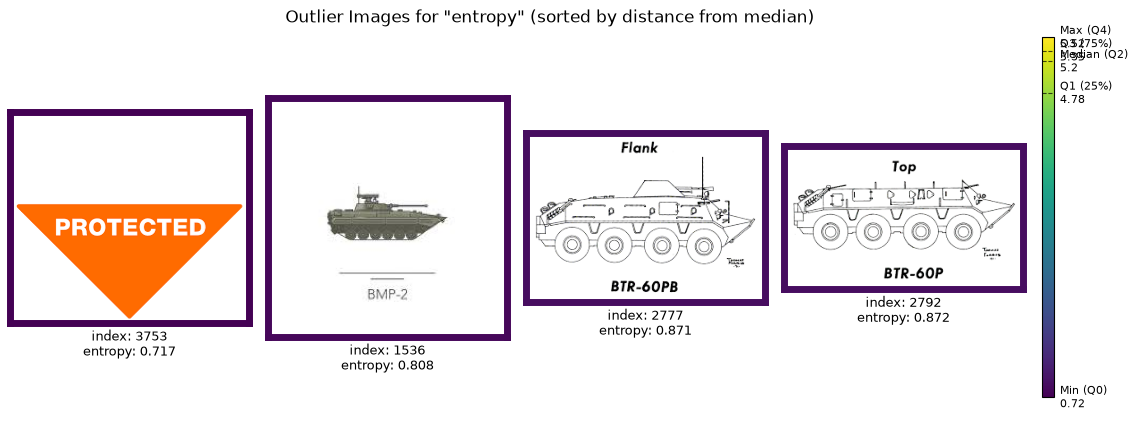

In [12]:
# Plot images flagged for "entropy"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "entropy", (1, 4))

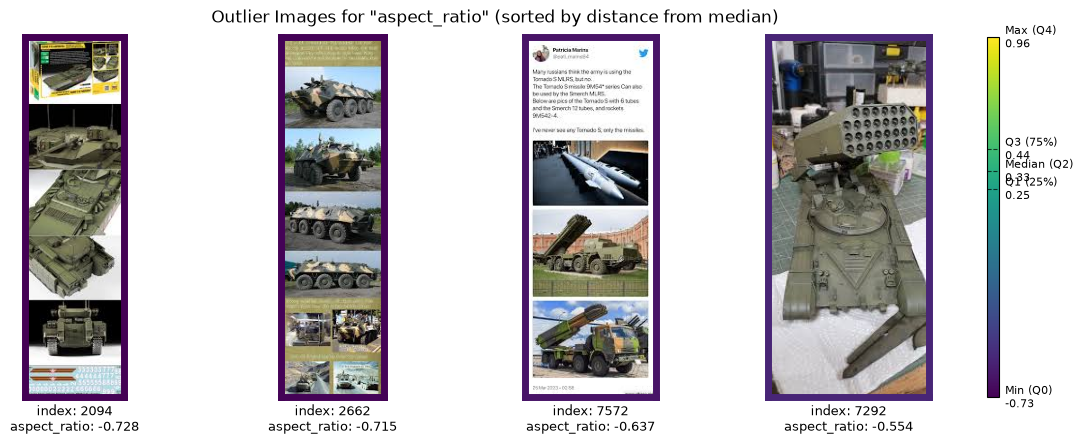

In [13]:
# Plot images flagged for "aspect_ratio"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "aspect_ratio", (1, 4))

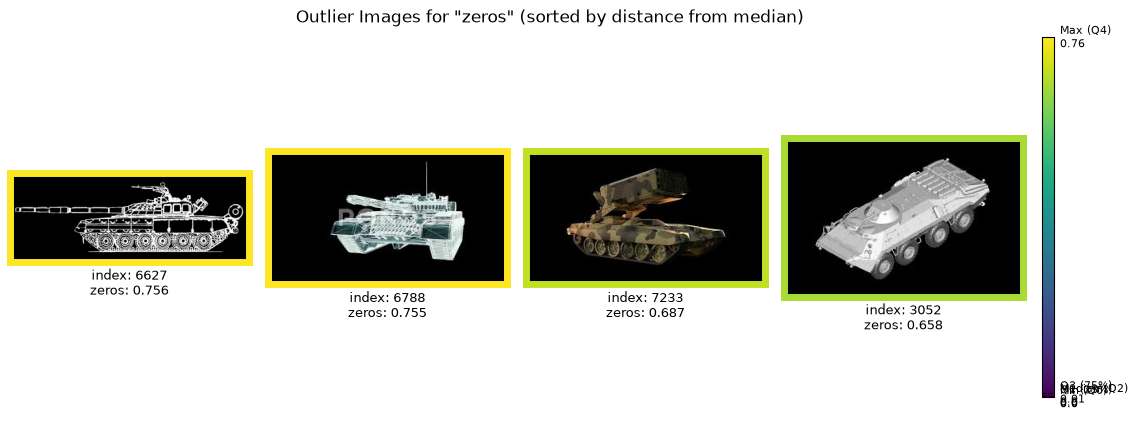

In [14]:
# Plot images flagged for "zeros"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "zeros", (1, 4))

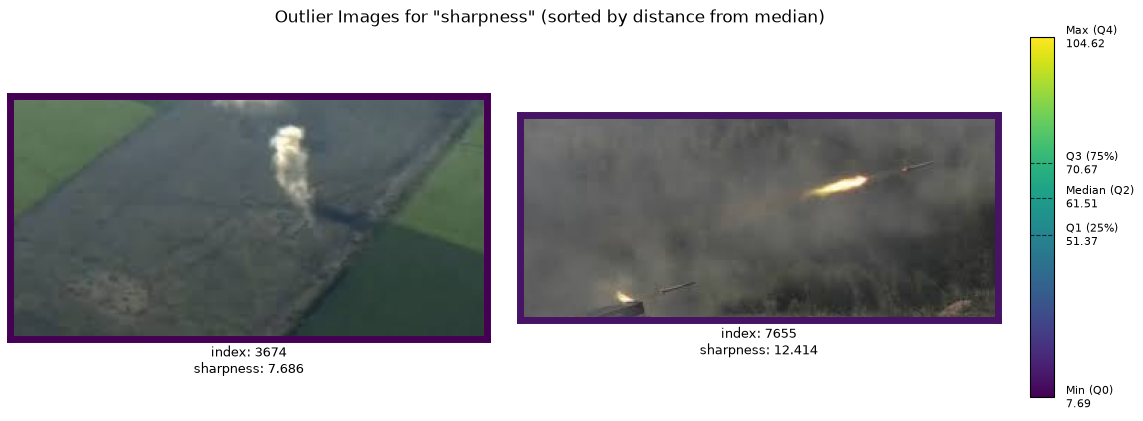

In [15]:
# Plot images flagged for "sharpness"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "sharpness", (1, 2))

In [16]:
# Initialize the Duplicates class. A hash radius of 0 counts two images as duplicates only when their hashes are
# identical
dups = Duplicates(ImageStats.HASH, hash_radius=0)

# Find the duplicates
results = dups.evaluate(ds, per_target=False)

In [17]:
# Count the duplicate groups by type, then view the first few
groups = results.data()
display(
    groups.group_by("dup_type", maintain_order=True).agg(
        pl.len().alias("groups"), pl.col("item_indices").list.len().sum().alias("images")
    )
)
display(groups.head(3))

dup_type,groups,images
str,u32,u32
"""exact""",67,139
"""near""",42,86


group_id,level,dup_type,item_indices,methods,orientation,differs_on,annotation_divergence
i64,str,str,list[i64],list[str],str,list[str],f64
0,"""item""","""exact""","[478, 6118]","[""xxhash""]",null,null,null
1,"""item""","""exact""","[487, 7811]","[""xxhash""]",null,null,null
2,"""item""","""exact""","[508, 3725]","[""xxhash""]",null,null,null


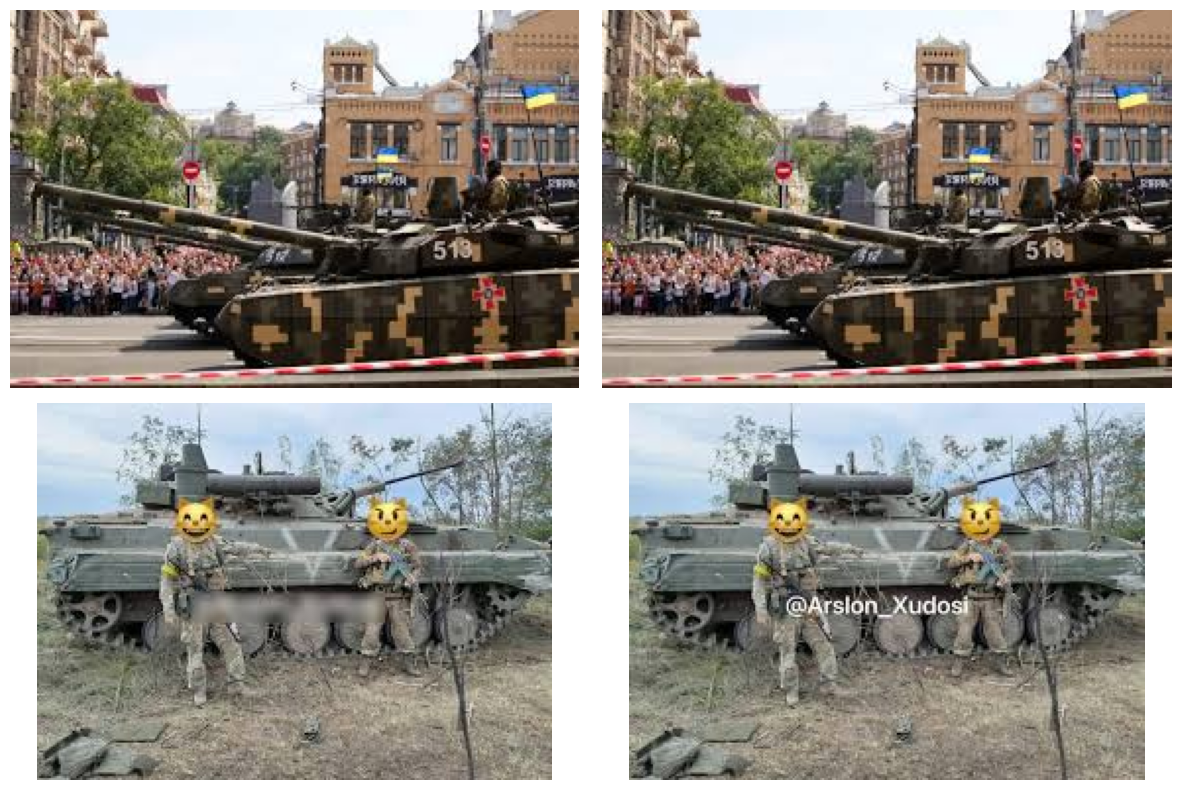

In [18]:
plot(ds, figsize=(12, 8), indices=(478, 6118, 1618, 7217), images_per_row=2)

In [19]:
def label_of(i: int) -> str:
    """Return the class name that the dataset gives to image `i`."""
    return ds.index2label[int(np.argmax(ds[i][1]))]


for kind in ("exact", "near"):
    found = groups.filter(pl.col("dup_type") == kind)["item_indices"].to_list()
    mixed = [group for group in found if len({label_of(i) for i in group}) > 1]
    print(f"{kind}: {len(mixed)} of {len(found)} groups hold images with different labels")

exact: 67 of 67 groups hold images with different labels
near: 31 of 42 groups hold images with different labels


In [20]:
# Create exact and duplicate images

# Copy images 23 and 46 to create exact duplicates
# Copy and crop images 5 and 589 by 2 pixels to create near duplicates
# Rotate image 100 by 90 degrees to create a rotated duplicate
# Mirror and rotate image 200 to create a mirrored+rotated duplicate
dupes = [
    ds[23][0],  # exact duplicate
    ds[46][0],  # exact duplicate
    ds[5][0][:, 2:-2, 2:-2],  # cropped near duplicate
    ds[589][0][:, :-2, 2:],  # cropped near duplicate
    np.rot90(ds[100][0], k=1, axes=(1, 2)),  # 90° rotation
    np.flip(np.rot90(ds[200][0], k=2, axes=(1, 2)), axis=2),  # 180° rotation + horizontal flip
]

dupes_stats = image_stats(dupes, stats=ImageStats.HASH)

In [21]:
# Find the duplicates appended to the dataset
duplicates = dups.from_stats([dups.stats, dupes_stats])

# View the groups that contain one of the added images. The other groups are the duplicates within the dataset.
display(duplicates.data().filter(pl.col("dataset_indices").list.contains(1)))

group_id,level,dup_type,item_indices,dataset_indices,methods,orientation,differs_on,annotation_divergence
i64,str,str,list[i64],list[i64],list[str],str,list[str],f64
0,"""item""","""exact""","[23, 0]","[0, 1]","[""xxhash""]",null,null,null
1,"""item""","""exact""","[46, 1]","[0, 1]","[""xxhash""]",null,null,null
69,"""item""","""near""","[5, 2]","[0, 1]","[""dhash"", ""phash""]","""same""",null,null
70,"""item""","""near""","[100, 4]","[0, 1]","[""dhash_d4"", ""phash_d4""]","""rotated""",null,null
71,"""item""","""near""","[200, 5]","[0, 1]","[""dhash_d4"", ""phash_d4""]","""rotated""",null,null
78,"""item""","""near""","[589, 3]","[0, 1]","[""dhash""]","""same""",null,null


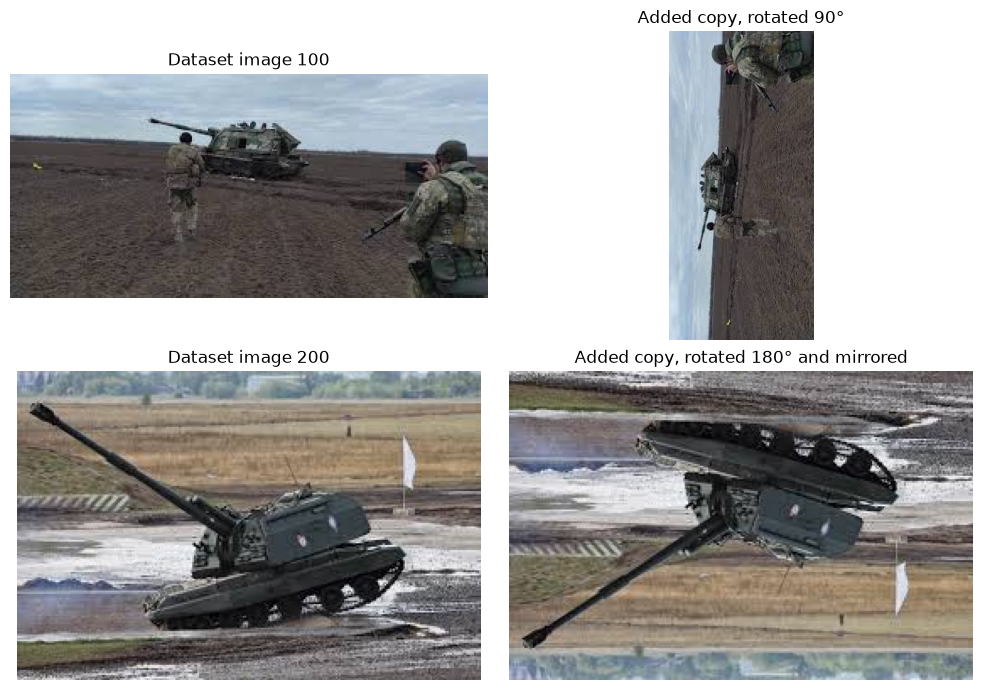

In [22]:
import matplotlib.pyplot as plt

# Each row holds an image from the dataset and the copy that was added to it
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
rotated = [(100, dupes[4], "rotated 90°"), (200, dupes[5], "rotated 180° and mirrored")]
for row, (source, copy, change) in zip(axs, rotated, strict=True):
    row[0].imshow(ds[source][0].transpose(1, 2, 0))
    row[0].set_title(f"Dataset image {source}")
    row[1].imshow(copy.transpose(1, 2, 0))
    row[1].set_title(f"Added copy, {change}")
for ax in axs.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [23]:
# TEST ASSERTION CELL ###
# Verify what the text says about the plotted images
flagged = {
    metric: set(outlier_imgs.data().filter(pl.col("metric_name") == metric)["item_index"].to_list())
    for metric in ("entropy", "aspect_ratio", "zeros", "sharpness")
}
assert {3753, 1536, 2777, 2792} <= flagged["entropy"]  # a sign, a vehicle on a white page, line drawings
assert {2094, 2662, 7572, 7292} <= flagged["aspect_ratio"]  # composites and a scale model
assert {6627, 6788, 7233, 3052} <= flagged["zeros"]  # line art and renders on black
least_sharp = outlier_imgs.data().filter(pl.col("metric_name") == "sharpness").sort("metric_value")["item_index"]
assert least_sharp.to_list()[:2] == [3674, 7655]  # the smoke plume and the launch

# Verify what the text says about the duplicate groups and their labels
exact_groups = groups.filter(pl.col("dup_type") == "exact")["item_indices"].to_list()
near_groups = groups.filter(pl.col("dup_type") == "near")["item_indices"].to_list()
assert exact_groups[0] == [478, 6118]  # the first pair plotted
assert [1618, 7217] in near_groups  # the second pair plotted
assert all(len({label_of(i) for i in group}) > 1 for group in exact_groups)  # "every exact group"
mixed_near = sum(len({label_of(i) for i in group}) > 1 for group in near_groups)
assert 0.5 < mixed_near / len(near_groups) < 0.95  # "most of the near groups"

# Verify what the text says about the six added images
added = {
    tuple(row["item_indices"]): row
    for row in duplicates.data().filter(pl.col("dataset_indices").list.contains(1)).iter_rows(named=True)
}
assert len(added) == 6
assert added[(23, 0)]["dup_type"] == added[(46, 1)]["dup_type"] == "exact"
for pair in ((5, 2), (589, 3)):
    assert added[pair]["dup_type"] == "near"
    assert added[pair]["orientation"] == "same"
assert set(added[(5, 2)]["methods"]) == {"phash", "dhash"}  # dhash finds both crops, phash only one
assert set(added[(589, 3)]["methods"]) == {"dhash"}
for pair in ((100, 4), (200, 5)):
    assert added[pair]["orientation"] == "rotated"
    assert set(added[pair]["methods"]) == {"phash_d4", "dhash_d4"}
larger_crop = image_stats([ds[589][0][:, :-5, 5:]], stats=ImageStats.HASH)
assert dups.from_stats([dups.stats, larger_crop]).data().filter(pl.col("dataset_indices").list.contains(1)).is_empty()